# 城市人口分析与预测 —— 探索性数据分析（EDA）

本 notebook 对应任务书模块一，需包含：
1. 数据读取与体检（shape / dtypes / 缺失率 / 城市覆盖）
2. 缺失值可视化
3. 人口规模分布与趋势
4. 关键特征相关系数矩阵
5. 至少 3 条真实数据规律

> 前置：先运行 `python scripts/run_all.py`（或至少完成预处理），生成 `data/processed/cleaned_data.csv`。

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 中文字体（Windows）
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid")

# 兼容两种打开方式：项目根目录 / notebooks 目录均可运行
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed" / "cleaned_data.csv"
FIG_DIR = ROOT / "outputs" / "figures"
os.makedirs(FIG_DIR, exist_ok=True)

df = pd.read_csv(DATA)
print("数据形状:", df.shape)
df.head()

数据形状: (693, 21)


,city_id,year,常住人口（万人）,户籍人口（万人）,urbanizationRate,人口密度（人/平方公里）,0-14,15-64,65+,wage,...,employeesNumber,pi_Employment,si_Employment,ti_Employment,人均可支配收入,人均消费支出,城镇居民消费支出,农村居民消费支出,城镇居民人均收入,农村居民人均收入
0,city1,2006,272.0,258.0,48.0,477.0,34.0,209.0,47.0,23872.0,...,162.0,0.0,71.0,52.0,31508.0,20356.0,23196.0,12440.0,35750.0,20256.0
1,city1,2007,277.0,258.0,48.0,483.0,34.0,209.0,47.0,26040.0,...,183.0,0.0,81.0,66.0,31508.0,20356.0,23196.0,12440.0,35750.0,20256.0
2,city1,2008,280.0,258.0,49.0,486.0,34.0,209.0,47.0,28504.0,...,199.0,0.0,87.0,77.0,31508.0,20356.0,23196.0,12440.0,35750.0,20256.0
3,city1,2009,282.0,259.0,50.0,491.0,34.0,209.0,47.0,31456.0,...,199.0,0.0,87.0,77.0,31508.0,20356.0,23196.0,12440.0,35750.0,20256.0
4,city1,2010,285.0,259.0,51.0,499.0,34.0,209.0,47.0,33840.0,...,180.0,0.0,89.0,56.0,31508.0,20356.0,23196.0,12440.0,35750.0,20256.0


## 1. 数据体检

回答：多少行？多少列？覆盖几座城市？年份范围？各列缺失率如何？

In [2]:
print("城市数:", df["city_id"].nunique())
print("年份范围:", int(df["year"].min()), "—", int(df["year"].max()))

missing = (df.isna().mean() * 100).sort_values(ascending=False)
missing[missing > 0].to_frame("缺失率(%)")

城市数: 40
年份范围: 2001 — 2021


,缺失率(%)


In [3]:
# 缺失率可视化
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]

if len(miss):
    fig, ax = plt.subplots(figsize=(8, max(3, len(miss) * 0.35)))
    ax.barh(miss.index[::-1], miss.values[::-1], color="#C44E52")
    ax.set_title("各字段缺失率")
    ax.set_xlabel("缺失率（%）")
    fig.savefig(os.path.join(FIG_DIR, "eda_missing_rate.png"), dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("清洗后无缺失值")

清洗后无缺失值


## 2. 人口规模分布与趋势

观察：规模差距有多大？哪些城市在增长、哪些在收缩？

In [4]:
LABEL = "常住人口（万人）"

last = df[df["year"] == df["year"].max()].nlargest(10, LABEL)
first = df[df["year"] == df["year"].max()].nsmallest(5, LABEL)
print("规模最大 10 城：")
print(last[["city_id", LABEL]].to_string(index=False))
print("\n规模最小 5 城：")
print(first[["city_id", LABEL]].to_string(index=False))

规模最大 10 城：
city_id  常住人口（万人）
 city17    1870.0
  city3    1763.0
  city5    1275.0
 city21    1194.0
 city28    1011.0
 city33     956.0
  city6     952.0
 city25     940.0
 city22     932.0
 city24     920.0

规模最小 5 城：
city_id  常住人口（万人）
  city4     116.0
 city39     219.0
 city20     225.0
 city23     245.0
 city10     251.0


In [5]:
# 按城市计算 2001→2021 增长率，找出增长最快与收缩最快的城市
span = df.dropna(subset=[LABEL]).groupby("city_id")["year"].agg(["min", "max"])
rows = []
for city in df["city_id"].unique():
    g = df[df["city_id"] == city].sort_values("year")
    if len(g) < 2:
        continue
    rows.append({"city_id": city,
                 "start": g[LABEL].iloc[0],
                 "end": g[LABEL].iloc[-1],
                 "growth": g[LABEL].iloc[-1] / g[LABEL].iloc[0] - 1})
growth = pd.DataFrame(rows).sort_values("growth", ascending=False)
print("增长最快 5 城：")
print(growth.head(5).to_string(index=False))
print("\n收缩最快 5 城：")
print(growth.tail(5).to_string(index=False))

增长最快 5 城：
city_id  start    end   growth
  city3  701.0 1763.0 1.514979
 city23  124.0  245.0 0.975806
 city17  990.0 1870.0 0.888889
  city5  679.0 1275.0 0.877761
  city6  534.0  952.0 0.782772

收缩最快 5 城：
city_id  start   end    growth
 city37  459.0 456.0 -0.006536
 city13  506.0 499.0 -0.013834
 city12  479.0 452.0 -0.056367
  city8  504.0 456.0 -0.095238
 city34  795.0 671.0 -0.155975


## 3. 关键特征相关系数

找出与常住人口相关性最高的特征。

与常住人口相关性最高的 8 个特征：
15-64              0.937412
employeesNumber    0.893014
ti_Employment      0.861426
0-14               0.817979
si_Employment      0.767114
户籍人口（万人）           0.708697
65+                0.594131
人口密度（人/平方公里）       0.498799
Name: 常住人口（万人）, dtype: float64


C:\Users\Ace00\Desktop\city-population-analysis\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 24120 (\N{CJK UNIFIED IDEOGRAPH-5E38}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\Ace00\Desktop\city-population-analysis\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 20303 (\N{CJK UNIFIED IDEOGRAPH-4F4F}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\Ace00\Desktop\city-population-analysis\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\Ace00\Desktop\city-population-analysis\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 21475 (\N{CJK UNIFIED IDEOGRAPH-53E3}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\Ace00\Desktop\city-population-analysis\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Us

C:\Users\Ace00\AppData\Local\Temp\ipykernel_17004\2326000397.py:10: UserWarning: Glyph 24120 (\N{CJK UNIFIED IDEOGRAPH-5E38}) missing from font(s) Arial.
  fig.savefig(os.path.join(FIG_DIR, "eda_correlation.png"), dpi=300, bbox_inches="tight")
C:\Users\Ace00\AppData\Local\Temp\ipykernel_17004\2326000397.py:10: UserWarning: Glyph 20303 (\N{CJK UNIFIED IDEOGRAPH-4F4F}) missing from font(s) Arial.
  fig.savefig(os.path.join(FIG_DIR, "eda_correlation.png"), dpi=300, bbox_inches="tight")
C:\Users\Ace00\AppData\Local\Temp\ipykernel_17004\2326000397.py:10: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from font(s) Arial.
  fig.savefig(os.path.join(FIG_DIR, "eda_correlation.png"), dpi=300, bbox_inches="tight")
C:\Users\Ace00\AppData\Local\Temp\ipykernel_17004\2326000397.py:10: UserWarning: Glyph 21475 (\N{CJK UNIFIED IDEOGRAPH-53E3}) missing from font(s) Arial.
  fig.savefig(os.path.join(FIG_DIR, "eda_correlation.png"), dpi=300, bbox_inches="tight")
C:\Users\Ace00\AppData\L

C:\Users\Ace00\Desktop\city-population-analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 24120 (\N{CJK UNIFIED IDEOGRAPH-5E38}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Ace00\Desktop\city-population-analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20303 (\N{CJK UNIFIED IDEOGRAPH-4F4F}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Ace00\Desktop\city-population-analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Ace00\Desktop\city-population-analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 21475 (\N{CJK UNIFIED IDEOGRAPH-53E3}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Ace00\Desktop\city-population-analysis\.venv\Lib\site-packages\

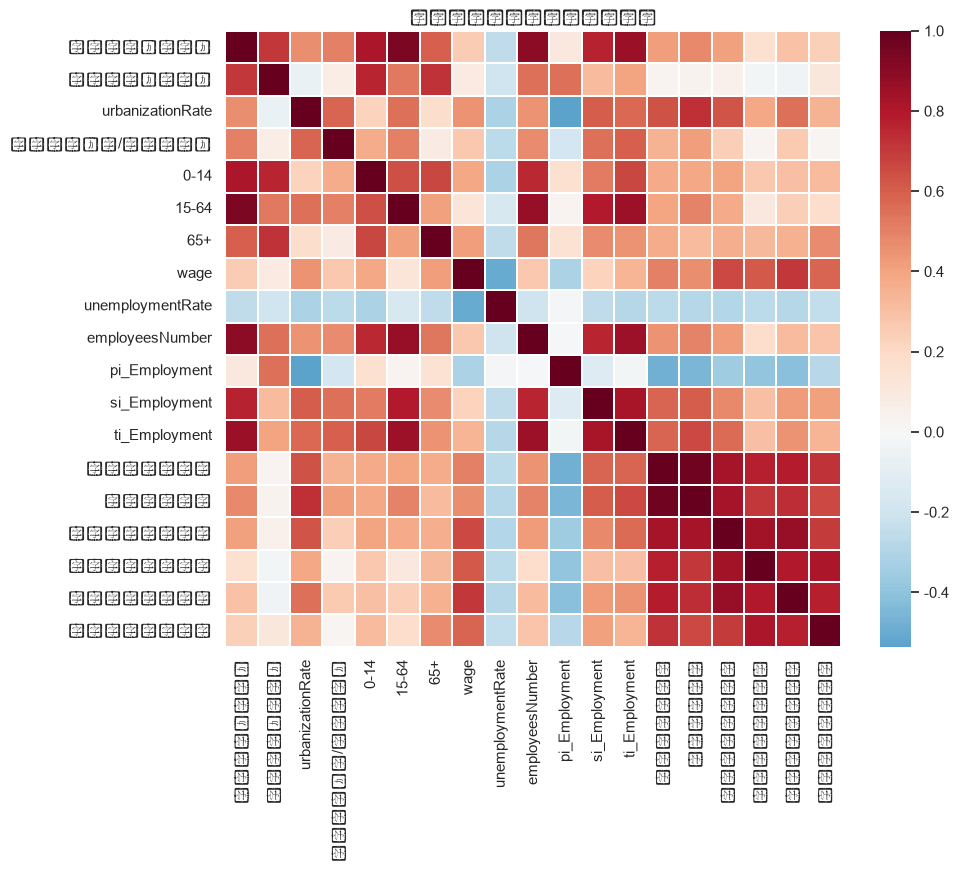

In [6]:
num = df.select_dtypes(include=[np.number]).drop(columns=["year"], errors="ignore")
corr = num.corr()

print("与常住人口相关性最高的 8 个特征：")
print(corr[LABEL].drop(LABEL).abs().sort_values(ascending=False).head(8))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, square=True, linewidths=0.3, ax=ax)
ax.set_title("清洗后数值特征相关系数矩阵")
fig.savefig(os.path.join(FIG_DIR, "eda_correlation.png"), dpi=300, bbox_inches="tight")
plt.show()

## 4. 结论（至少 3 条，须由上面的输出支撑）

1. 2021 年常住人口最多的是 **city17（1870 万人）**，最少的是 **city4（116 万人）**，相差约 **16.1 倍**；前 5 城合计占 40 城总量的 27.3%，规模高度集中。
2. 2001—2021 年 **35 城增长、5 城收缩**；累计涨幅最大的是 city3（+151.5%），跌幅最大的是 city34（-15.6%）、city8（-9.5%）、city12（-5.6%）。
3. 与常住人口相关性最高的是 **15-64 岁人口（0.937）**，其次是从业人员数（0.893）与户籍人口（0.709）。这些变量与人口规模同源、共线性强，因此建模时未把年龄段绝对人口数放入特征，只保留占比类指标。